# EN3160 Assignment 02: Fitting and Alignment

**Name:** Peramunage D.S.
**Index Number:** 230473G
**GitHub Profile:** https://github.com/DulenSandiw

## Question 1: Sunflower Detection

Detect sunflower centres using the scale-normalized Laplacian
of Gaussian and local extrema across position and scale.

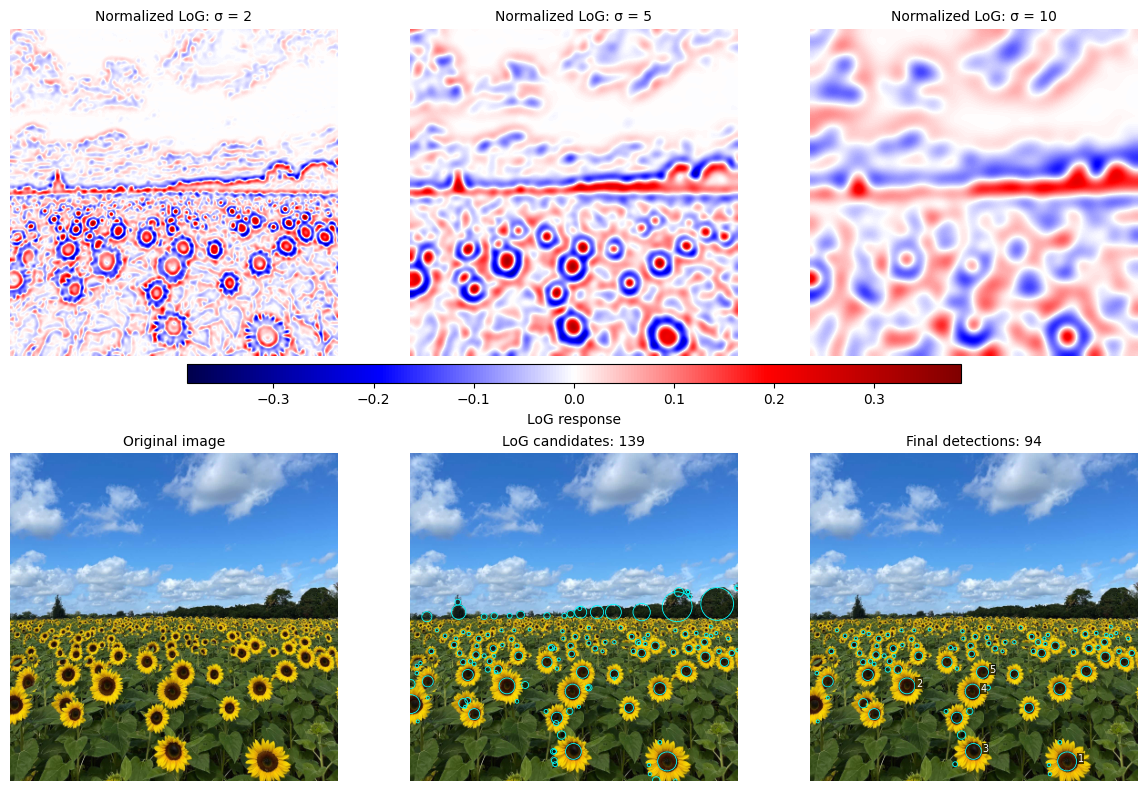

Candidates: 139  →  After colour/boundary checks: 101  →  After suppression: 94

Detection σ: 1.20–20.00 px (32 logarithmically spaced scales)
Including guard scales: 1.10–21.90 px
LoG threshold: 0.20 | Yellow fraction: 0.55 | Suppression factor: 0.8

Five largest retained dark disks
Rank     x     y    Radius(px)    Sigma(px)
   1   282   338         10.42         7.37
   2   106   255          8.69         6.15
   3   179   327          8.69         6.15
   4   178   261          7.94         5.61
   5   189   240          6.62         4.68

Coordinates use the reduced image; origin is top-left.
Multiply x, y and radius by 4 for approximate original-image values.


In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_laplace, maximum_filter
# 1. LOAD AND PREPARE THE IMAGE

image = cv.imread(
    "a2images/a2images/the_berry_farms_sunflower_field.jpeg",
    cv.IMREAD_REDUCED_COLOR_4
)
if image is None:
    raise FileNotFoundError("Check the sunflower image path.")
gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
gray_float = gray.astype(np.float64) / 255.0
image_rgb = cv.cvtColor(image, cv.COLOR_BGR2RGB)

height, width = gray.shape

# 2. BUILD THE SCALE-NORMALIZED LoG SCALE SPACE

sigmas = np.geomspace(1.2, 20.0, 32)
ratio = sigmas[1] / sigmas[0]

# Guard scales allow comparison at both ends of the main range.
search_sigmas = np.concatenate([
    [sigmas[0] / ratio],
    sigmas,
    [sigmas[-1] * ratio]
])
scale_space = np.stack([
    sigma**2 * gaussian_laplace(gray_float, sigma=sigma)
    for sigma in search_sigmas
])

# 3. FIND STRONG LOCAL MAXIMA IN POSITION AND SCALE

threshold = 0.20

neighbourhood_max = maximum_filter(
    scale_space,
    size=(3, 3, 3),
    mode="nearest"
)
is_peak = (
    (scale_space == neighbourhood_max)
    & (scale_space > threshold)
)

# Guard scales are not reported as detections.
is_peak[0] = False
is_peak[-1] = False
scale_indices, ys, xs = np.where(is_peak)
detected_sigmas = search_sigmas[scale_indices]
radii = np.sqrt(2) * detected_sigmas

# 4. CHECK FOR YELLOW PETALS AROUND EACH DARK DISK

hsv = cv.cvtColor(image, cv.COLOR_BGR2HSV)

yellow_mask = cv.inRange(
    hsv,
    np.array([18, 90, 90], dtype=np.uint8),
    np.array([40, 255, 255], dtype=np.uint8)
) > 0
yy, xx = np.ogrid[:height, :width]
filtered_blobs = []
for k, x, y, radius in zip(
    scale_indices, xs, ys, radii
):
    # Reject central disks crossing the image boundary.
    if (
        x - radius < 0
        or y - radius < 0
        or x + radius >= width
        or y + radius >= height
    ):
        continue

    distance = np.hypot(xx - x, yy - y)

    ring = (
        (distance >= 0.9 * radius)
        & (distance <= 2.0 * radius)
    )

    yellow_fraction = yellow_mask[ring].mean()

    if yellow_fraction >= 0.55:
        filtered_blobs.append({
            "x": int(x),
            "y": int(y),
            "radius": float(radius),
            "sigma": float(search_sigmas[k]),
            "response": float(scale_space[k, y, x])
        })

# 5. SUPPRESS NEARBY OVERLAPPING DETECTIONS

filtered_blobs.sort(
    key=lambda blob: blob["response"],
    reverse=True
)

final_blobs = []
for blob in filtered_blobs:
    too_close = any(
        np.hypot(
            blob["x"] - kept["x"],
            blob["y"] - kept["y"]
        ) < 0.8 * (blob["radius"] + kept["radius"])
        for kept in final_blobs
    )

    if not too_close:
        final_blobs.append(blob)
largest_blobs = sorted(
    final_blobs,
    key=lambda blob: blob["radius"],
    reverse=True
)[:5]

# 6. DISPLAY ALL IMAGE RESULTS IN ONE COMPACT FIGURE
fig, axes = plt.subplots(
    2, 3,
    figsize=(12, 7.8),
    layout="constrained"
)

# First row: compare LoG responses using a shared colour scale.
example_sigmas = [2, 5, 10]
example_responses = [
    sigma**2 * gaussian_laplace(gray_float, sigma=sigma)
    for sigma in example_sigmas
]
limit = max(
    np.max(np.abs(response))
    for response in example_responses
)
for ax, sigma, response in zip(
    axes[0], example_sigmas, example_responses
):
    response_plot = ax.imshow(
        response,
        cmap="seismic",
        vmin=-limit,
        vmax=limit
    )
    ax.set_title(f"Normalized LoG: σ = {sigma}", fontsize=10)
    ax.axis("off")
fig.colorbar(
    response_plot,
    ax=axes[0].tolist(),
    orientation="horizontal",
    shrink=0.65,
    pad=0.02,
    aspect=40,
    label="LoG response"
)
# Second row: original image, raw candidates, final detections.
titles = [
    "Original image",
    f"LoG candidates: {len(xs)}",
    f"Final detections: {len(final_blobs)}"
]
for ax, title in zip(axes[1], titles):
    ax.imshow(image_rgb)
    ax.set_title(title, fontsize=10)
    ax.axis("off")
# Raw candidate circles.
for x, y, radius in zip(xs, ys, radii):
    axes[1, 1].add_patch(plt.Circle(
        (x, y),
        radius,
        fill=False,
        edgecolor="cyan",
        linewidth=0.6
    ))
# Final retained circles.
for blob in final_blobs:
    axes[1, 2].add_patch(plt.Circle(
        (blob["x"], blob["y"]),
        blob["radius"],
        fill=False,
        edgecolor="cyan",
        linewidth=0.6
    ))
# Label the five largest circles in the final panel.
for rank, blob in enumerate(largest_blobs, start=1):
    axes[1, 2].text(
        blob["x"] + blob["radius"] + 1,
        blob["y"],
        str(rank),
        color="white",
        fontsize=7,
        bbox=dict(
            facecolor="black",
            alpha=0.7,
            edgecolor="none",
            pad=0.5
        )
    )

plt.show()

# 7. PRINT COMPACT NUMERICAL RESULTS
print(
    f"Candidates: {len(xs)}  →  "
    f"After colour/boundary checks: {len(filtered_blobs)}  →  "
    f"After suppression: {len(final_blobs)}"
)
print(
    f"\nDetection σ: {sigmas[0]:.2f}–{sigmas[-1]:.2f} px "
    f"({len(sigmas)} logarithmically spaced scales)"
)
print(
    f"Including guard scales: "
    f"{search_sigmas[0]:.2f}–{search_sigmas[-1]:.2f} px"
)
print(
    f"LoG threshold: {threshold:.2f} | "
    "Yellow fraction: 0.55 | Suppression factor: 0.8"
)
print("\nFive largest retained dark disks")
print("Rank     x     y    Radius(px)    Sigma(px)")

for rank, blob in enumerate(largest_blobs, start=1):
    print(
        f"{rank:>4} "
        f"{blob['x']:>5} "
        f"{blob['y']:>5} "
        f"{blob['radius']:>13.2f} "
        f"{blob['sigma']:>12.2f}"

print("\nCoordinates use the reduced image; origin is top-left.")
print("Multiply x, y and radius by 4 for approximate original-image values.")

The method detected 139 initial LoG candidates, reduced to 101 after colour and boundary checks and 94 after overlap suppression. Filtering removed the obvious tree detections while retaining many sunflower centres. The largest retained dark disk was centred at (282, 338) with radius 10.42 pixels, using σ = 7.37 pixels. Some false detections and missed flowers remain. All measurements refer to the reduced image, and the circles approximate the dark centres rather than the outer petals.